In [2]:
import os
from pathlib import Path
import numpy as np
from PIL import Image
from sklearn.model_selection import train_test_split
import tensorflow as tf
import keras
from keras import layers
from keras.applications import MobileNetV2
import matplotlib.pyplot as plt

print("TensorFlow Version:", tf.__version__)
print("Keras Version:", keras.__version__)

TensorFlow Version: 2.21.0
Keras Version: 3.12.4


In [3]:
# ==========================================
# CONFIGURATION & PATHS
# ==========================================
IMG_SIZE = 224
BATCH_SIZE = 16
EPOCHS = 15

# Update this path to your actual dataset directory
DATA_DIR = Path(r"C:\Users\ACER\Documents\AI-Project-Road-classifire-") 

broken_dir = DATA_DIR / "Broken"
not_broken_dir = DATA_DIR / "Not_Broken"

print(f"Broken images directory: {broken_dir}")
print(f"Not Broken images directory: {not_broken_dir}")

Broken images directory: C:\Users\ACER\Documents\AI-Project-Road-classifire-\Broken
Not Broken images directory: C:\Users\ACER\Documents\AI-Project-Road-classifire-\Not_Broken


In [4]:
# ==========================================
# LOAD & PREPROCESS IMAGES INTO ARRAYS
# ==========================================
images = []
labels = []

print("Loading and scaling images from directories...")

# Load Broken images (Label = 1)
for img_path in broken_dir.glob("*.*"):
    if img_path.suffix.lower() in ['.jpg', '.jpeg', '.png']:
        try:
            img = Image.open(img_path).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
            images.append(np.array(img, dtype=np.float32) / 255.0)  # Scale pixel values to [0.0, 1.0]
            labels.append(1)
        except Exception as e:
            pass

# Load Not_Broken images (Label = 0)
for img_path in not_broken_dir.glob("*.*"):
    if img_path.suffix.lower() in ['.jpg', '.jpeg', '.png']:
        try:
            img = Image.open(img_path).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
            images.append(np.array(img, dtype=np.float32) / 255.0)  # Scale pixel values to [0.0, 1.0]
            labels.append(0)
        except Exception as e:
            pass

X = np.array(images)
y = np.array(labels)

print(f"\nSuccessfully loaded {len(X)} total images.")
print(f"Dataset Array Shape: {X.shape}")
print(f"Pixel Value Range: Min = {X.min()}, Max = {X.max()}")

Loading and scaling images from directories...

Successfully loaded 204 total images.
Dataset Array Shape: (204, 224, 224, 3)
Pixel Value Range: Min = 0.0, Max = 1.0


In [5]:
# ==========================================
# SPLIT DATA (70% Train, 15% Validation, 15% Test)
# ==========================================
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

print(f"Training samples:   {len(X_train)} (Broken: {np.sum(y_train == 1)}, Not Broken: {np.sum(y_train == 0)})")
print(f"Validation samples: {len(X_val)} (Broken: {np.sum(y_val == 1)}, Not Broken: {np.sum(y_val == 0)})")
print(f"Test samples:       {len(X_test)} (Broken: {np.sum(y_test == 1)}, Not Broken: {np.sum(y_test == 0)})")

Training samples:   142 (Broken: 77, Not Broken: 65)
Validation samples: 31 (Broken: 17, Not Broken: 14)
Test samples:       31 (Broken: 16, Not Broken: 15)


In [6]:
# ==========================================
# BUILD MOBILENETV2 MODEL
# ==========================================
keras.utils.set_random_seed(42)

# Load pre-trained MobileNetV2 base model
base_model = MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = False  # Freeze pre-trained weights

# Input layer
inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

# MobileNetV2 expects input pixel range [-1.0, 1.0]
x = layers.Rescaling(2.0, offset=-1.0)(inputs)
x = base_model(x, training=False)

# Custom classification head
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation='relu')(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(1, activation='sigmoid')(x)

model = keras.Model(inputs, outputs, name="mobilenetv2_road_model")

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=["accuracy", keras.metrics.Precision(name="precision"), keras.metrics.Recall(name="recall")],
)

model.summary()

Model: "mobilenetv2_road_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [7]:
# ==========================================
# TRAIN THE MODEL
# ==========================================
print("Starting model training...\n")
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1
)

Starting model training...

Epoch 1/15
9/9 ━━━━━━━━━━━━━━━━━━━━ 8s 450ms/step - accuracy: 0.5986 - loss: 0.6584 - precision: 0.5980 - recall: 0.7922 - val_accuracy: 0.6452 - val_loss: 0.6136 - val_precision: 0.6500 - val_recall: 0.7647
Epoch 2/15
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 236ms/step - accuracy: 0.7394 - loss: 0.5329 - precision: 0.7941 - recall: 0.7013 - val_accuracy: 0.7419 - val_loss: 0.5380 - val_precision: 0.7647 - val_recall: 0.7647
Epoch 3/15
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 226ms/step - accuracy: 0.8099 - loss: 0.4445 - precision: 0.8289 - recall: 0.8182 - val_accuracy: 0.7419 - val_loss: 0.4862 - val_precision: 0.7647 - val_recall: 0.7647
Epoch 4/15
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 230ms/step - accuracy: 0.7746 - loss: 0.4443 - precision: 0.7711 - recall: 0.8312 - val_accuracy: 0.7419 - val_loss: 0.4510 - val_precision: 0.7647 - val_recall: 0.7647
Epoch 5/15
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 234ms/step - accuracy: 0.8028 - loss: 0.3843 - precision: 0.8101 - recall: 0.8312 - val_accuracy: 0.8

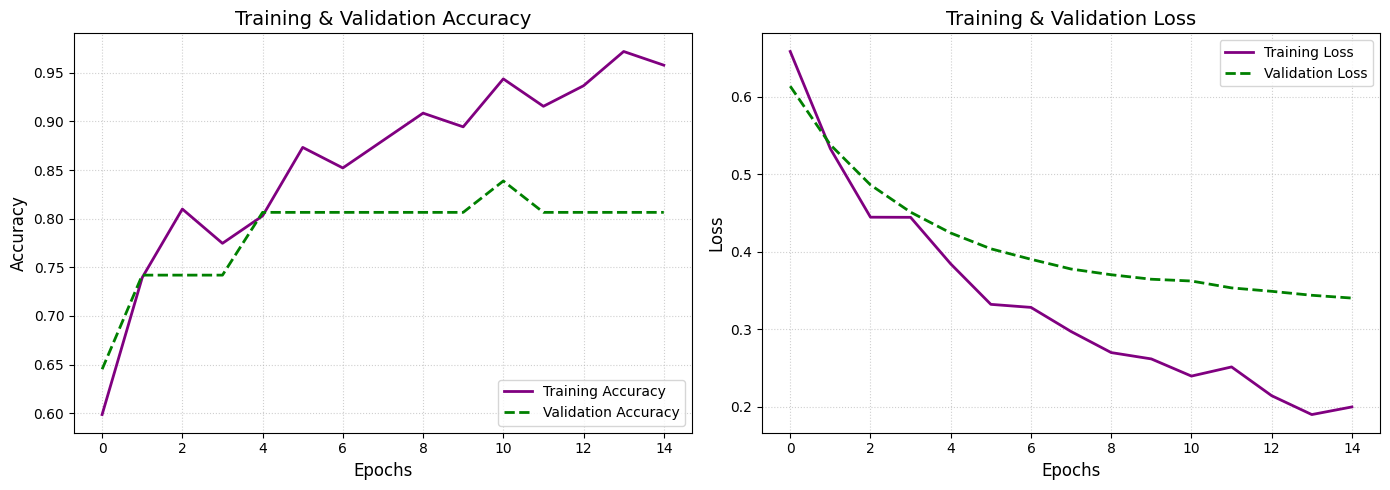

In [8]:
# ==========================================
# PLOT TRAINING & VALIDATION GRAPHS
# ==========================================
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(len(acc))

plt.figure(figsize=(14, 5))

# Accuracy Curve
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy', color='purple', linewidth=2)
plt.plot(epochs_range, val_acc, label='Validation Accuracy', color='green', linestyle='--', linewidth=2)
plt.title('Training & Validation Accuracy', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.legend(loc='lower right')
plt.grid(True, linestyle=':', alpha=0.6)

# Loss Curve
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss', color='purple', linewidth=2)
plt.plot(epochs_range, val_loss, label='Validation Loss', color='green', linestyle='--', linewidth=2)
plt.title('Training & Validation Loss', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.legend(loc='upper right')
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

In [19]:
# ==========================================
# EVALUATE ON TEST SET & SAVE MODEL
# ==========================================
test_results = model.evaluate(X_test, y_test, verbose=1)

print(f"\n==============================")
print(f"   FINAL TEST SET PERFORMANCE ")
print(f"==============================")
print(f"Test Loss:      {test_results[0]:.4f}")
print(f"Test Accuracy:  {test_results[1] * 100:.2f}%")
print(f"Test Precision: {test_results[2]:.4f}")
print(f"Test Recall:    {test_results[3]:.4f}")

# Save model permanently
model.save("road_damage_mobilenet.keras")
print("\nModel saved successfully as 'road_damage_mobilenet.keras'!")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 447ms/step - accuracy: 0.9032 - loss: 0.2501 - precision: 0.9333 - recall: 0.8750

   FINAL TEST SET PERFORMANCE 
Test Loss:      0.2501
Test Accuracy:  90.32%
Test Precision: 0.9333
Test Recall:    0.8750

Model saved successfully as 'road_damage_mobilenet.keras'!


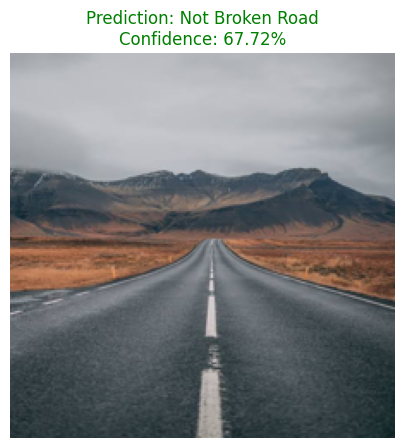

Prediction: Not Broken Road
Confidence: 67.72%


In [44]:
from tkinter import Tk, filedialog
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# If running as a standalone python file, make sure your model is loaded:
# model = tf.keras.models.load_model("best_road_model.keras")

def predict_image(img):
    # Prepare the image to match MobileNetV2 requirements (224x224)
    img = img.convert("RGB")
    img = img.resize((224, 224))

    img_array = np.array(img, dtype="float32") / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    # Ask the trained model for a prediction
    probability = model.predict(img_array, verbose=0)[0][0]

    if probability >= 0.5:
        label = "Broken Road"
        confidence = probability * 100
    else:
        label = "Not Broken Road"
        confidence = (1 - probability) * 100

    # Display the image and prediction
    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.title(f"Prediction: {label}\nConfidence: {confidence:.2f}%", 
              color="red" if label == "Broken Road" else "green")
    plt.axis("off")
    plt.show()

    print("Prediction:", label)
    print(f"Confidence: {confidence:.2f}%")

def upload_photo():
    root = Tk()
    root.withdraw()
    root.attributes("-topmost", True)

    file_path = filedialog.askopenfilename(
        title="Choose a road photo",
        filetypes=[
            ("Image files", "*.jpg *.jpeg *.png *.bmp *.webp")
        ]
    )

    root.destroy()

    if file_path:
        img = Image.open(file_path)
        predict_image(img)
    else:
        print("No image selected.")

upload_photo()